In [6]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input

In [7]:

base_dir = Path("/kaggle/input/datasets/misrakahmed/vegetable-image-dataset/Vegetable Images")

train_dir = base_dir / "train"
test_dir = base_dir / "test"
validation_dir = base_dir / "validation"

In [8]:
print("Train:", train_dir.exists())
print("Test:", test_dir.exists())
print("Validation:", validation_dir.exists())

Train: True
Test: True
Validation: True


In [9]:
def count_images(folder_path):
    folder_path = Path(folder_path)
    counts = {}
    for class_folder in sorted(folder_path.iterdir()):
        if class_folder.is_dir():
            n = len([f for f in class_folder.iterdir()
                     if f.suffix.lower() in (".jpg", ".jpeg", ".png")])
            counts[class_folder.name] = n
    return counts

train_counts = count_images(train_dir)
test_counts = count_images(test_dir)
val_counts = count_images(validation_dir)

print("Train:", train_counts)
print("Test:", test_counts)
print("Validation:", val_counts)

Train: {'Bean': 1000, 'Bitter_Gourd': 1000, 'Bottle_Gourd': 1000, 'Brinjal': 1000, 'Broccoli': 1000, 'Cabbage': 1000, 'Capsicum': 1000, 'Carrot': 1000, 'Cauliflower': 1000, 'Cucumber': 1000, 'Papaya': 1000, 'Potato': 1000, 'Pumpkin': 1000, 'Radish': 1000, 'Tomato': 1000}
Test: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}
Validation: {'Bean': 200, 'Bitter_Gourd': 200, 'Bottle_Gourd': 200, 'Brinjal': 200, 'Broccoli': 200, 'Cabbage': 200, 'Capsicum': 200, 'Carrot': 200, 'Cauliflower': 200, 'Cucumber': 200, 'Papaya': 200, 'Potato': 200, 'Pumpkin': 200, 'Radish': 200, 'Tomato': 200}


In [10]:
train_df = pd.DataFrame(list(train_counts.items()), columns=["Vegetable", "Train Count"])
test_df = pd.DataFrame(list(test_counts.items()), columns=["Vegetable", "Test Count"])
val_df = pd.DataFrame(list(val_counts.items()), columns=["Vegetable", "Validation Count"])

summary_df = train_df.merge(test_df, on="Vegetable").merge(val_df, on="Vegetable")
summary_df

,Vegetable,Train Count,Test Count,Validation Count
0,Bean,1000,200,200
1,Bitter_Gourd,1000,200,200
2,Bottle_Gourd,1000,200,200
3,Brinjal,1000,200,200
4,Broccoli,1000,200,200
5,Cabbage,1000,200,200
6,Capsicum,1000,200,200
7,Carrot,1000,200,200
8,Cauliflower,1000,200,200
9,Cucumber,1000,200,200


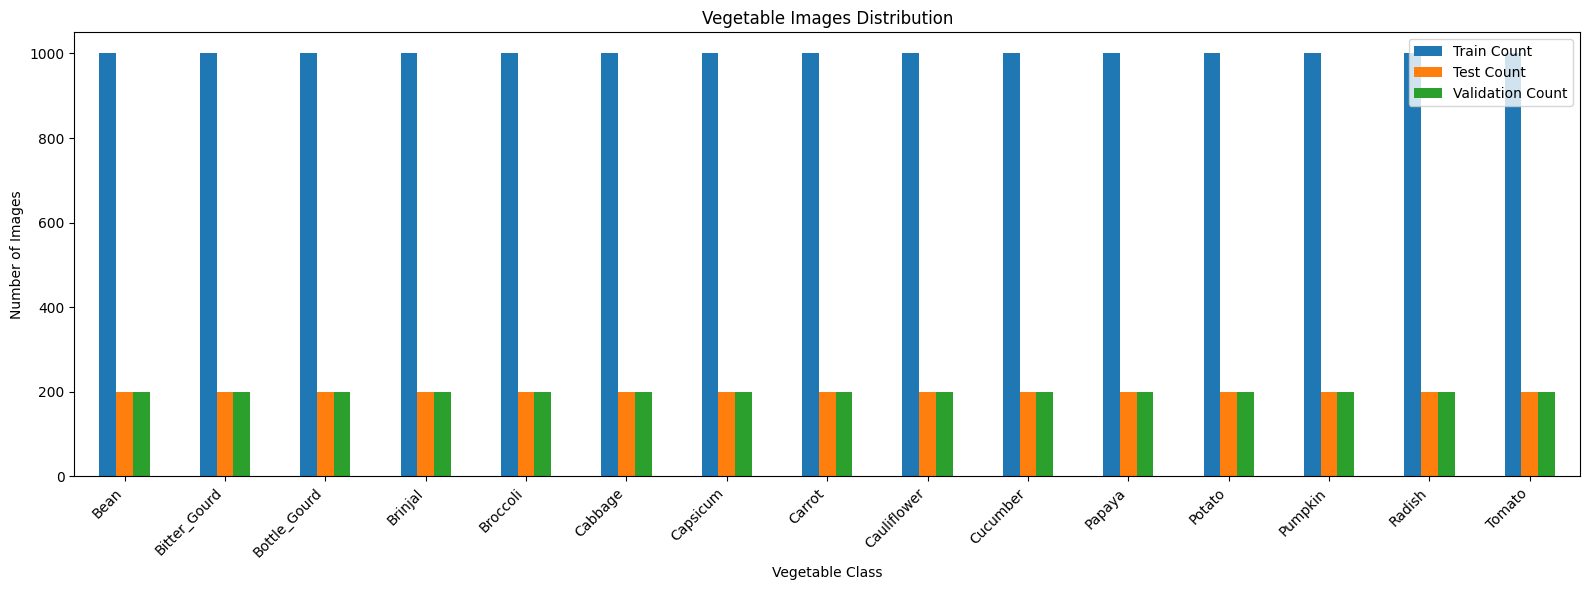

In [11]:
summary_df.plot(
    x="Vegetable",
    y=["Train Count", "Test Count", "Validation Count"],
    kind="bar",
    figsize=(16, 6)
)

plt.title("Vegetable Images Distribution")
plt.xlabel("Vegetable Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [12]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
VALIDATION_SPLIT = 0.2

train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    validation_split=VALIDATION_SPLIT
)

validation_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=VALIDATION_SPLIT
)

In [13]:
train_ds = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    seed=SEED
)

val_ds = validation_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="validation",
    seed=SEED
)

Found 12000 images belonging to 15 classes.
Found 3000 images belonging to 15 classes.


In [16]:
model = Sequential([
    Input(shape=(224, 224, 3)),

    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(512, activation="relu"),
    Dropout(0.5),

    Dense(15, activation="softmax")
])

In [15]:
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [17]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         7,695 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,403,791 (169.39 MB)

 Trainable params: 44,403,791 (169.39 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
train_eval_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    validation_split=VALIDATION_SPLIT
)

train_eval_ds = train_eval_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    subset="training",
    seed=SEED,
    shuffle=False
)

Found 12000 images belonging to 15 classes.


In [19]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=[early_stopping]
)

Epoch 1/20


2026-10-16 15:52:15.059381: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-16 15:52:15.207698: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  2/375 ━━━━━━━━━━━━━━━━━━━━ 23s 63ms/step - accuracy: 0.0547 - loss: 4.0396

I0000 00:00:1792165938.572476     161 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


375/375 ━━━━━━━━━━━━━━━━━━━━ 274s 710ms/step - accuracy: 0.5177 - loss: 1.4571 - val_accuracy: 0.8060 - val_loss: 0.6305
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 155s 414ms/step - accuracy: 0.7447 - loss: 0.7728 - val_accuracy: 0.8237 - val_loss: 0.5300
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 150s 401ms/step - accuracy: 0.8193 - loss: 0.5710 - val_accuracy: 0.8930 - val_loss: 0.3367
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 150s 399ms/step - accuracy: 0.8569 - loss: 0.4503 - val_accuracy: 0.9267 - val_loss: 0.2411
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 149s 398ms/step - accuracy: 0.8810 - loss: 0.3825 - val_accuracy: 0.9217 - val_loss: 0.2485
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 149s 398ms/step - accuracy: 0.8978 - loss: 0.3289 - val_accuracy: 0.9487 - val_loss: 0.1740
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 151s 403ms/step - accuracy: 0.9042 - loss: 0.3014 - val_accuracy: 0.9080 - val_loss: 0.3049
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 154s 412ms/step - accuracy: 0.9137 - loss: 0.26

In [20]:
train_loss, train_accuracy = model.evaluate(
    train_eval_ds,
    verbose=1
)

val_loss, val_accuracy = model.evaluate(
    val_ds,
    verbose=1
)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Validation Accuracy: {val_accuracy:.4f}")

print(f"Training Loss: {train_loss:.4f}")
print(f"Validation Loss: {val_loss:.4f}")

375/375 ━━━━━━━━━━━━━━━━━━━━ 31s 83ms/step - accuracy: 0.9852 - loss: 0.0490
94/94 ━━━━━━━━━━━━━━━━━━━━ 7s 77ms/step - accuracy: 0.9783 - loss: 0.0790
Training Accuracy: 0.9852
Validation Accuracy: 0.9783
Training Loss: 0.0490
Validation Loss: 0.0790


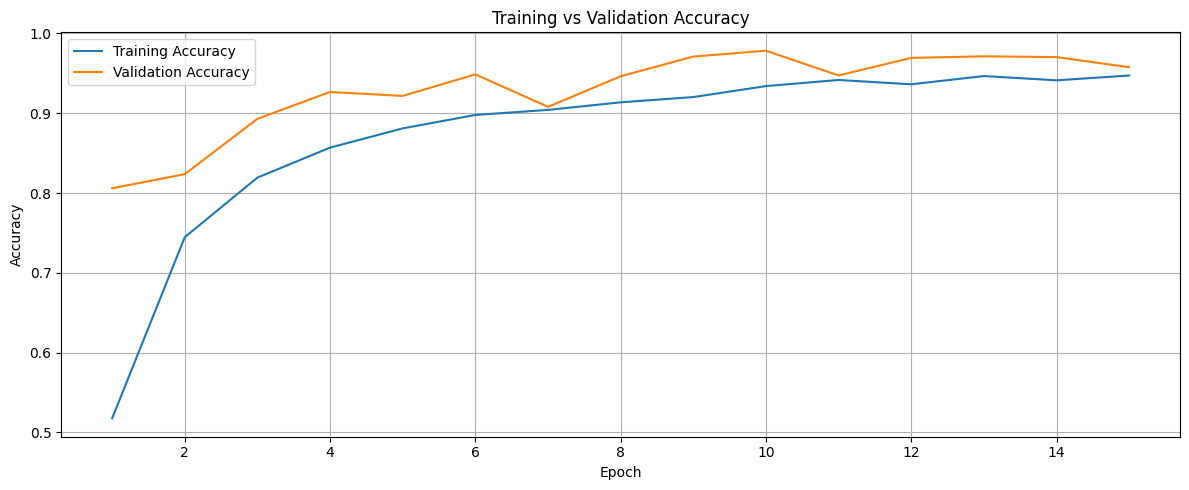

In [22]:
epochs_range = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(12, 5))

plt.plot(
    epochs_range,
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

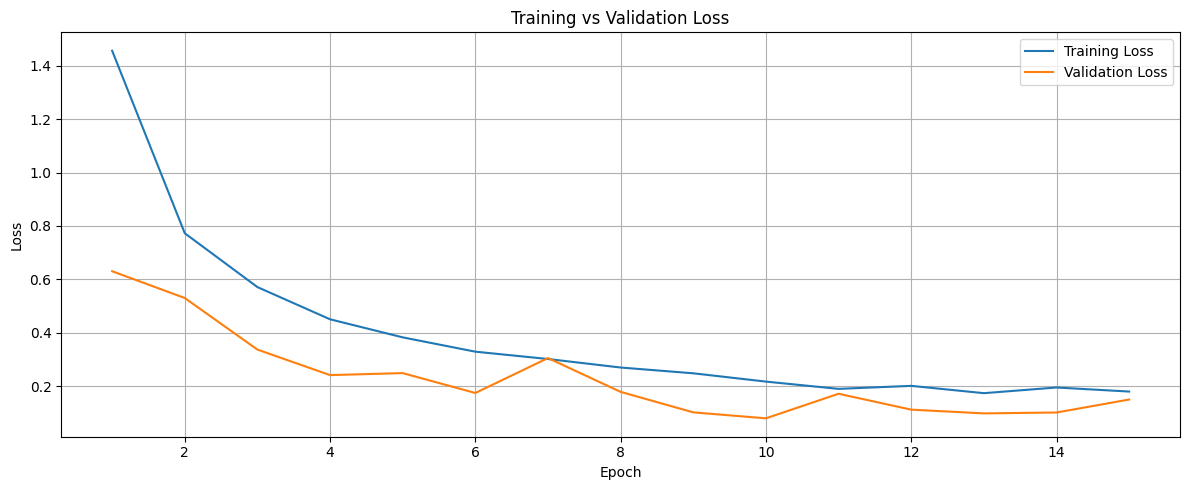

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(
    epochs_range,
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

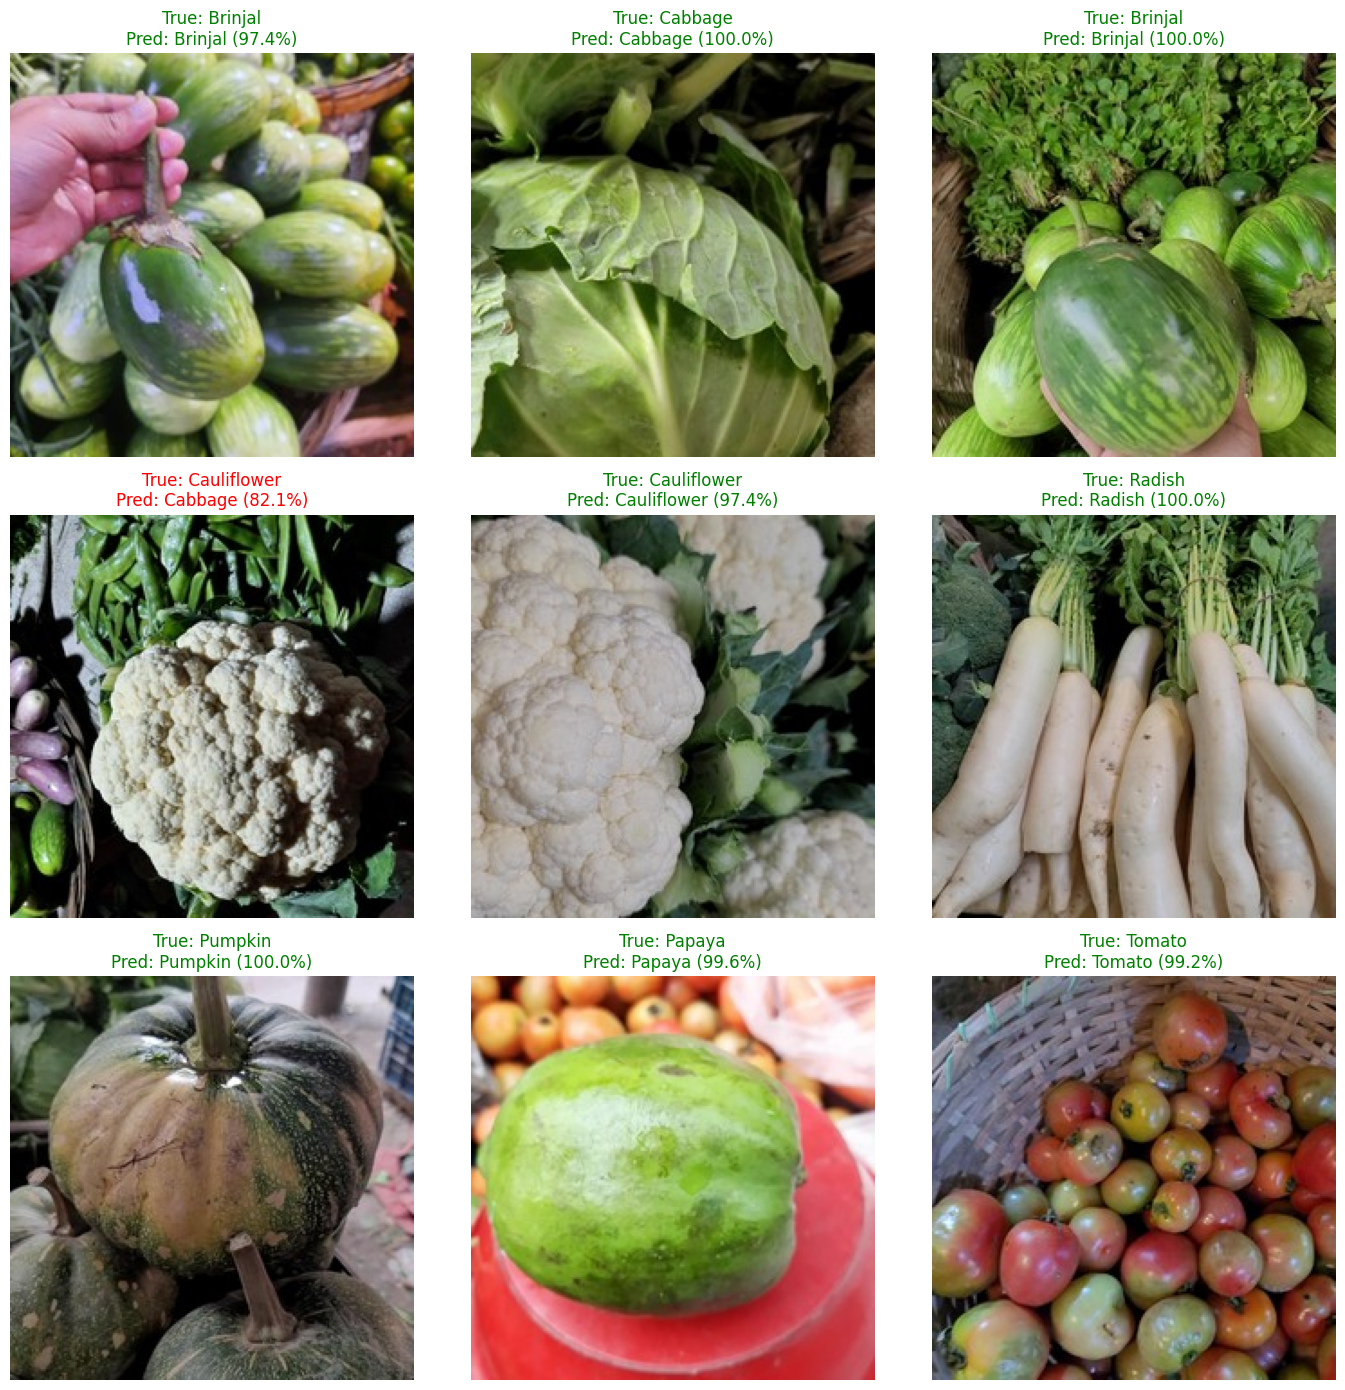

In [25]:

import matplotlib.pyplot as plt
import numpy as np

class_names = list(train_ds.class_indices.keys())

images, labels = next(val_ds)
predictions = model.predict(images, verbose=0)

plt.figure(figsize=(14, 14))

for i in range(min(9, len(images))):
    true_label = int(np.argmax(labels[i])) if labels.ndim > 1 else int(labels[i])
    pred_label = int(np.argmax(predictions[i]))
    confidence = predictions[i][pred_label] * 100

    image = np.clip(images[i] * 255, 0, 255).astype("uint8")

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)

    color = "green" if true_label == pred_label else "red"

    plt.title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]} ({confidence:.1f}%)",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()


In [26]:
model.save("vegetable_cnn_model.keras")

In [27]:
import os

print(os.path.exists("vegetable_cnn_model.keras"))

True
